# Module 8 — Financial Probability: Returns, Option Pricing and Risk

**Probability Simulation Laboratory** · Module 8 of 8 (capstone)

## Learning objectives
1. distinguish **simple** and **log** returns and know which is additive in time and which is additive across assets;
2. quantify how **fat tails** change the probability of extreme moves relative to the normal model;
3. price European and path-dependent options by **Monte Carlo**, check against **Black–Scholes**, and improve efficiency with antithetic and control variates;
4. understand the roles of the *risk-neutral* and *real-world* drift;
5. estimate **Value-at-Risk** and **Expected Shortfall** with historical, normal and Student-$t$ models, and quantify estimation error;
6. simulate **GARCH(1,1)** returns and see volatility clustering, and **model risk** when a normal VaR is applied to them.

## Research objective
How can stochastic simulation help estimate potential financial outcomes, and how can wrong model assumptions mislead those estimates?

> **Important.** Everything in this notebook is a *simulation under assumed models*. No real market data is used, none of the numbers is a forecast, and nothing here is investment advice.

In [1]:
import sys, pathlib

# Locate the repository root so the notebook runs from anywhere inside the repo.
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / "src" / "plab").exists():
    if ROOT == ROOT.parent:
        raise RuntimeError("Run this notebook from inside the probability-simulation-laboratory repository.")
    ROOT = ROOT.parent
for p in [ROOT / "src", *sorted(ROOT.glob("0*/src"))]:
    sys.path.insert(0, str(p))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from plab import make_rng, save_fig, set_style, wilson_interval, mean_ci

set_style()
RESULTS = ROOT / "08_quantitative_finance" / "results"
rng = make_rng(20261031)          # one seeded Generator -> every number below is reproducible
pd.set_option("display.precision", 5)
pd.set_option("display.width", 140)

In [2]:
import finance as fin          # 08_quantitative_finance/src/finance.py
import brownian as bm          # for GBM terminal values

## 1. Mathematical background

**Returns.** For prices $S_t$: simple return $R_t=S_t/S_{t-1}-1$; log return $r_t=\ln(S_t/S_{t-1})=\ln(1+R_t)$. Log returns add over *time* ($\ln(S_T/S_0)=\sum r_t$); simple returns add over *assets in a portfolio* ($R_p=\sum w_iR_i$). Under GBM, $r_t\overset{iid}\sim\mathcal N\big((\mu-\tfrac12\sigma^2)\Delta t,\sigma^2\Delta t\big)$ and $R_t$ is lognormal-minus-one (right-skewed, bounded below by $-1$).

**Tail risk.** A normal variable exceeds $k$ standard deviations (either side) with probability $2\bar\Phi(k)$: $0.27\%$ at $k=3$, $6.3\times10^{-5}$ at $k=4$, $5.7\times10^{-7}$ at $k=5$. A Student-$t_\nu$ variable (scaled to unit variance) has *polynomial* tails $P(|X|>x)\sim x^{-\nu}$, so far more extreme moves; its kurtosis is $3+6/(\nu-4)$ for $\nu>4$ and infinite for $\nu\le4$.

**Risk-neutral pricing.** In the Black–Scholes market (GBM stock, constant rate $r$) the arbitrage-free price of a payoff $h(S_T)$ is the discounted expectation under the risk-neutral measure $\mathbb Q$, where the stock has drift $r$:
$$V_0=e^{-rT}\,\mathbb E^{\mathbb Q}[h(S_T)],\qquad S_T=S_0\exp\big((r-\tfrac12\sigma^2)T+\sigma\sqrt T\,Z\big).$$
For a call, $C=S_0\Phi(d_1)-Ke^{-rT}\Phi(d_2)$, $d_{1,2}=\dfrac{\ln(S_0/K)+(r\pm\tfrac12\sigma^2)T}{\sigma\sqrt T}$; $\Delta=\Phi(d_1)$; vega $=S_0\varphi(d_1)\sqrt T>0$. Put–call parity: $C-P=S_0-Ke^{-rT}$. The real-world drift $\mu$ does **not** enter the price; using it in the simulation prices the wrong thing.

**Monte Carlo.** $\hat V=\frac1n\sum e^{-rT}h(S_T^{(i)})$ is unbiased with $SE=s/\sqrt n$ (Module 5). *Antithetic variates* use $(Z,-Z)$ pairs; *control variates* subtract $\beta(Y-\mathbb EY)$ for a correlated $Y$ with known mean (here $S_T$ with $\mathbb E^{\mathbb Q}S_T=S_0e^{rT}$ for the European call, and the geometric-average Asian payoff for the arithmetic Asian).

**Value-at-Risk and Expected Shortfall.** For a loss $L$ with continuous cdf and level $\alpha$: $\mathrm{VaR}_\alpha=F_L^{-1}(\alpha)$ and $\mathrm{ES}_\alpha=\mathbb E[L\mid L\ge\mathrm{VaR}_\alpha]$. Normal: $\mathrm{VaR}=\mu+\sigma z_\alpha$, $\mathrm{ES}=\mu+\sigma\varphi(z_\alpha)/(1-\alpha)$. VaR says nothing about the size of losses beyond the threshold; ES does, and is a coherent risk measure (VaR is not sub-additive in general).

**GARCH(1,1).** $r_t=\sigma_tz_t$, $\sigma_t^2=\omega+\alpha r_{t-1}^2+\beta\sigma_{t-1}^2$. Stationary iff $\alpha+\beta<1$, with $\mathbb Er_t^2=\omega/(1-\alpha-\beta)$. Even with Gaussian $z_t$ the unconditional distribution has excess kurtosis, and $r_t^2$ has positive autocorrelation (volatility clustering) while $r_t$ itself is serially uncorrelated.

## Experiment 8.1

**A. Experiment title.** Simple versus log returns under geometric Brownian motion.

**B. Research question.** How different are simple and log returns, which is additive in time, and what does each look like statistically?

**C. Mathematical foundation.**

GBM with $S_0=100,\ \mu=0.08,\ \sigma=0.2$, $252$ daily steps on $[0,1]$. Daily: $r_t\sim\mathcal N((\mu-\sigma^2/2)/252,\ \sigma^2/252)$. Annual log return $=\sum r_t\sim\mathcal N(\mu-\sigma^2/2,\sigma^2)=\mathcal N(0.06,0.04)$. Annual simple return $R=e^{r}-1$ has mean $e^{\mu}-1=0.0833$, positive skewness, and cannot go below $-100\%$. For small $x$: $\ln(1+x)\approx x-x^2/2$.

**D. Theoretical prediction.**

(i) $\sum_tr_t=\ln(S_T/S_0)$ exactly; the compounded simple returns also give $S_T/S_0$. (ii) Annual log returns: mean $\approx0.06$, sd $\approx0.2$, skewness $\approx0$ and normal (KS); annual simple returns: mean $\approx0.0833$ and skewness $\approx+0.6$ (lognormal skewness $(e^{\sigma^2}+2)\sqrt{e^{\sigma^2}-1}=0.6$). (iii) The gap between simple and log returns is negligible at $1\%$ and large for $-50\%$.

**E. Experimental design.**

$20{,}000$ GBM paths with $252$ steps (exact simulation at grid points). Compute daily simple and log returns with `fin.simple_returns` / `fin.log_returns`; compare annual statistics; tabulate the conversion for illustrative return sizes.

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

max |sum of daily log returns - ln(S_T/S_0)|: 9.43689570931383e-16
max |prod(1+R) - S_T/S_0|: 6.439293542825908e-15
fin.log_returns agrees with np.diff(log S): True  | simple: True
KS test of annual log return normality: D=0.0045, p=0.80


,mean,sd,skewness,min,max,theory mean,theory skewness
annual LOG return,0.06073,0.20164,0.01158,-0.78526,0.87495,0.06000,0.00000
annual SIMPLE return,0.08445,0.22126,0.64164,-0.54400,1.39876,0.08329,0.61429


,log r = ln(1+R),r - R,-R^2/2 (2nd-order approx. of r - R)
simple R,,,
0.01,0.00995,-0.00005,-0.00005
0.05,0.04879,-0.00121,-0.00125
0.10,0.09531,-0.00469,-0.00500
0.20,0.18232,-0.01768,-0.02000
-0.20,-0.22314,-0.02314,-0.02000
-0.50,-0.69315,-0.19315,-0.12500
-0.90,-2.30259,-1.40259,-0.40500


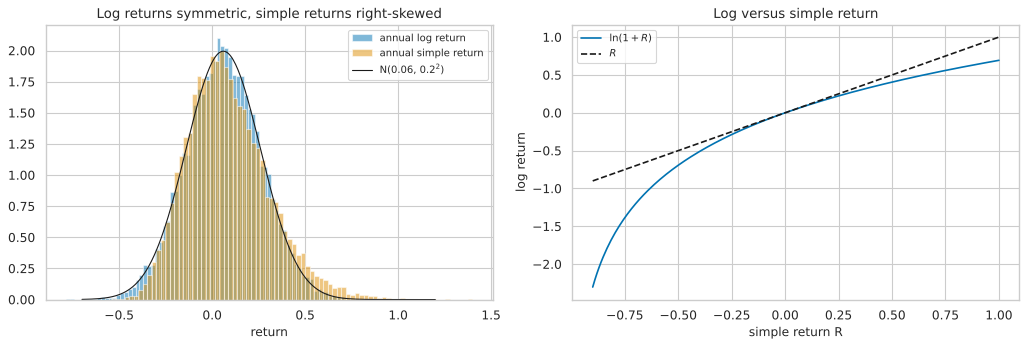

PosixPath('/home/claude/probability-simulation-laboratory/08_quantitative_finance/results/exp8_1_returns.png')

In [3]:
# F. Implementation ------------------------------------------------------------------
# fin.simple_returns(S) = S_t/S_{t-1} - 1 ;  fin.log_returns(S) = ln(S_t/S_{t-1})
rng = make_rng(20261031 + 81)
S0, mu, sigma = 100.0, 0.08, 0.2
t, S = bm.gbm_exact_paths(S0, mu, sigma, 1.0, 252, 20_000, rng)
Rsimple = np.diff(S, axis=1) / S[:, :-1]                   # same as fin.simple_returns applied per path
r_log = np.diff(np.log(S), axis=1)
print("max |sum of daily log returns - ln(S_T/S_0)|:", np.abs(r_log.sum(axis=1) - np.log(S[:, -1] / S0)).max())
print("max |prod(1+R) - S_T/S_0|:", np.abs(np.prod(1 + Rsimple, axis=1) - S[:, -1] / S0).max())
print("fin.log_returns agrees with np.diff(log S):", np.allclose(fin.log_returns(S[0]), r_log[0]), " | simple:", np.allclose(fin.simple_returns(S[0]), Rsimple[0]))

ann_log = r_log.sum(axis=1)
ann_simple = S[:, -1] / S0 - 1
th_skew = (np.exp(sigma ** 2) + 2) * np.sqrt(np.exp(sigma ** 2) - 1)
rows = {"annual LOG return": ann_log, "annual SIMPLE return": ann_simple}
tab = pd.DataFrame({k: dict(mean=v.mean(), sd=v.std(ddof=1), skewness=stats.skew(v), min=v.min(), max=v.max()) for k, v in rows.items()}).T
tab["theory mean"] = [mu - sigma ** 2 / 2, np.exp(mu) - 1]
tab["theory skewness"] = [0.0, th_skew]
display(tab)
tab.to_csv(RESULTS / "exp8_1_annual_returns.csv")
ks = stats.kstest((ann_log - ann_log.mean()) / ann_log.std(ddof=1), "norm")
print(f"KS test of annual log return normality: D={ks.statistic:.4f}, p={ks.pvalue:.2f}")

conv = pd.DataFrame({"simple R": [0.01, 0.05, 0.10, 0.20, -0.20, -0.50, -0.90]})
conv["log r = ln(1+R)"] = np.log1p(conv["simple R"]); conv["r - R"] = conv["log r = ln(1+R)"] - conv["simple R"]
conv["-R^2/2 (2nd-order approx. of r - R)"] = -conv["simple R"] ** 2 / 2
display(conv.set_index("simple R"))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].hist(ann_log, bins=80, density=True, alpha=0.5, label="annual log return"); ax[0].hist(ann_simple, bins=80, density=True, alpha=0.5, label="annual simple return")
g = np.linspace(-0.7, 1.2, 300); ax[0].plot(g, stats.norm.pdf(g, mu - sigma ** 2 / 2, sigma), "k", lw=1, label="N(0.06, 0.2$^2$)"); ax[0].legend(); ax[0].set(title="Log returns symmetric, simple returns right-skewed", xlabel="return")
x = np.linspace(-0.9, 1.0, 200); ax[1].plot(x, np.log1p(x), label="$\\ln(1+R)$"); ax[1].plot(x, x, "k--", label="$R$"); ax[1].legend(); ax[1].set(title="Log versus simple return", xlabel="simple return R", ylabel="log return")
fig.tight_layout(); save_fig(fig, RESULTS, "exp8_1_returns.png")

**H. Theoretical versus empirical comparison.**

Both identities hold to machine precision. The annual log return is normal with mean $\approx0.06$ and sd $\approx0.20$; the annual simple return has mean $\approx0.083$ and clearly positive skewness (see table for the simulated value against $0.6$). The conversion table shows $r-R\approx-R^2/2$ for small $R$ and large differences for big losses (a $-50\%$ simple return is a $-69\%$ log return).

**I. Interpretation.**

Log returns are the natural variable for modelling an individual asset through time (additive, unbounded, normal under GBM); simple returns are needed for portfolio aggregation and for what an investor actually earns. Arithmetic-mean simple return $>$ log return mean by about $\sigma^2/2$ — the same volatility drag as in Module 7. Never average simple returns over time to get compound growth.

**J. Limitations.**

GBM assumes constant volatility, normal log returns and no jumps. Real daily log returns are not normal (Experiment 8.2). A KS test with $20{,}000$ observations is sensitive to tiny departures; simulated normality is exact here by construction.

**K. Research conclusion.**

Log returns add over time and are normal under GBM; simple returns compound, are right-skewed and bounded below by $-1$; the two differ materially only for large moves.

**L. Further investigation.**

Compare the distribution of the annualised return across horizons ($1$ day to $10$ years) for the same $\mu,\sigma$ and watch the probability of a negative *simple* return versus horizon.

## Experiment 8.2

**A. Experiment title.** Fat tails: frequency of $k$-sigma moves under the normal and Student-$t$ models with equal variance.

**B. Research question.** How wrong is a normal model about the frequency of extreme returns, if the true distribution is fat-tailed?

**C. Mathematical foundation.**

Let $X$ be standardised to mean 0 and variance 1. Normal: $P(|X|>k)=2\bar\Phi(k)$. Student $t_4$ scaled by $\sqrt{(\nu-2)/\nu}$: $P(|X|>k)=2\,\bar F_{t_\nu}\big(k\sqrt{\nu/(\nu-2)}\big)$. For $\nu=4$ this gives, e.g., $0.0132$ at $k=3$ (computed with `fin.student_t_tail_probability`). Daily returns of equity indices are often reported to have kurtosis well above $3$ (Cont, 2001); we do *not* use data here, only the model comparison.

**D. Theoretical prediction.**

At $k=3,4,5$ the $t_4$ model gives probabilities larger than the normal by factors of roughly $5$, $76$ and $3{,}700$ (at $k=2$ the two are nearly equal, ratio $1.04$); empirical frequencies in a large simulated sample match the corresponding theory. A $5\sigma$ day under the normal model happens about once in $6{,}900$ years of $252$ trading days, but about once in $1.9$ years under $t_4$.

**E. Experimental design.**

$2{,}000{,}000$ draws from each distribution; count exceedances; compare with theory and compute return periods in years of $252$ trading days.

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

sample variances: normal 1.0010, t4 0.9995 (both theory 1);  sample excess kurtosis: normal 0.01, t4 17.2 (theory 0 and infinite)


,normal_theory,normal_sim,t4_theory,t4_sim,ratio_t_over_normal,normal_return_period_years,t4_return_period_years
k,,,,,,,
2,0.0455,0.0456,0.0474,0.0473,1.04,0.0872,0.0837
3,0.0027,0.00277,0.0132,0.0133,4.9,1.47,0.3
4,6.33e-05,7.1e-05,0.00481,0.00481,76,62.6,0.825
5,5.73e-07,0,0.00211,0.00212,3.68e+03,6.92e+03,1.88


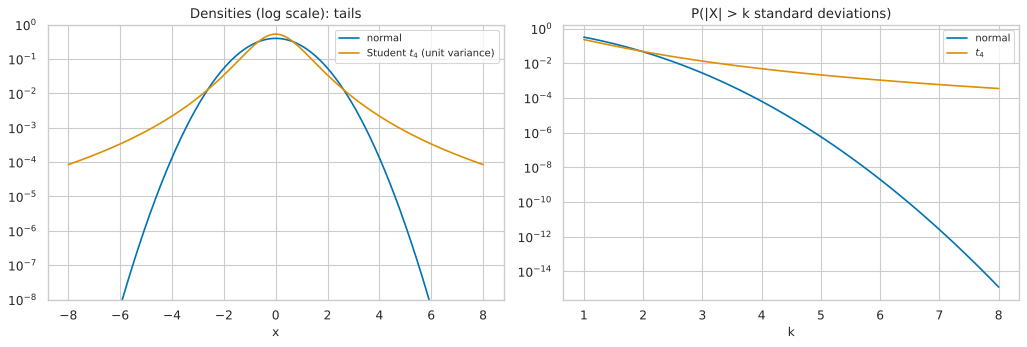

PosixPath('/home/claude/probability-simulation-laboratory/08_quantitative_finance/results/exp8_2_fat_tails.png')

In [4]:
# F. Implementation ------------------------------------------------------------------
# fin.normal_tail_probability(k) and fin.student_t_tail_probability(k, nu) give the exact two-sided tail probabilities
rng = make_rng(20261031 + 82)
nu, N = 4.0, 2_000_000
x_norm = rng.standard_normal(N)
x_t = rng.standard_t(nu, N) * np.sqrt((nu - 2) / nu)        # rescale to unit variance
print(f"sample variances: normal {x_norm.var():.4f}, t4 {x_t.var():.4f} (both theory 1);  sample excess kurtosis: normal {stats.kurtosis(x_norm):.2f}, t4 {stats.kurtosis(x_t):.1f} (theory 0 and infinite)")

rows = []
for k in (2, 3, 4, 5):
    p_n, p_t = fin.normal_tail_probability(k), fin.student_t_tail_probability(k, nu)
    rows.append(dict(k=k, normal_theory=p_n, normal_sim=np.mean(np.abs(x_norm) > k), t4_theory=p_t, t4_sim=np.mean(np.abs(x_t) > k),
                     ratio_t_over_normal=p_t / p_n, normal_return_period_years=1 / (p_n * 252), t4_return_period_years=1 / (p_t * 252)))
tab = pd.DataFrame(rows).set_index("k")
tab.to_csv(RESULTS / "exp8_2_tail_frequencies.csv")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(tab)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
g = np.linspace(-8, 8, 800)
ax[0].semilogy(g, stats.norm.pdf(g), label="normal"); ax[0].semilogy(g, stats.t.pdf(g * np.sqrt(nu / (nu - 2)), nu) * np.sqrt(nu / (nu - 2)), label="Student $t_4$ (unit variance)")
ax[0].set(ylim=(1e-8, 1), title="Densities (log scale): tails", xlabel="x"); ax[0].legend()
ks_ = np.linspace(1, 8, 100)
ax[1].semilogy(ks_, [fin.normal_tail_probability(k) for k in ks_], label="normal"); ax[1].semilogy(ks_, [fin.student_t_tail_probability(k, nu) for k in ks_], label="$t_4$")
ax[1].set(title="P(|X| > k standard deviations)", xlabel="k"); ax[1].legend()
fig.tight_layout(); save_fig(fig, RESULTS, "exp8_2_fat_tails.png")

**H. Theoretical versus empirical comparison.**

Simulated exceedance frequencies agree with the exact tail formulas where the counts are large enough (at $k=5$ the normal count is of order one in $2\times10^6$ draws, i.e. very noisy — compare only the $t_4$ column and the theory column). See the table for the ratios and return periods: the normal model calls $4\sigma$ and $5\sigma$ events essentially impossible, while $t_4$ makes them occasional events.

**I. Interpretation.**

With the same mean and variance, the *tail* differs dramatically: variance alone is not a sufficient risk description. Risk management based on a normal assumption systematically under-weights rare large losses ("black swans" in popular language; just the polynomial tails of heavy-tailed laws in mathematical language).

**J. Limitations.**

The choice $\nu=4$ is a stylised illustration and was not fitted to data; real tail indices vary by asset and period and are estimated with large uncertainty. Rare-event frequencies in simulation have high relative error (the $k=5$ normal row).

**K. Research conclusion.**

At equal variance, a $t_4$ distribution has tail probabilities that exceed the normal's by factors that grow quickly with $k$.

**L. Further investigation.**

Fit a Student-$t$ and a normal to real index returns (data not available in this environment) and compare tail probabilities; use importance sampling (Module 5) to estimate the $5\sigma$ normal tail precisely.

## Experiment 8.3

**A. Experiment title.** Monte Carlo pricing of a European call: Black–Scholes benchmark, variance reduction, put–call parity and the wrong-measure error.

**B. Research question.** How accurately can Monte Carlo reproduce the Black–Scholes price, how much do antithetic and control variates help, and what happens if the real-world drift is used instead of $r$?

**C. Mathematical foundation.**

$S_0=K=100$, $r=0.05$, $\sigma=0.2$, $T=1$: $C_{BS}=10.4506$, $P_{BS}=5.5735$, $S_0-Ke^{-rT}=4.8771$. The MC estimator $\hat C$ is unbiased, $SE\propto n^{-1/2}$; the antithetic and control-variate estimators have the same expectation and smaller variance (the $S_T$ control has a high correlation $\rho$ with the call payoff, giving variance factor $1-\rho^2$; the antithetic factor is $\tfrac12(1+\rho_a)$ per $n$ draws). If we simulate with $\mu=0.15$ instead of $r$ and still discount at $r$, the estimator converges to $e^{-rT}\mathbb E^{\mu}[(S_T-K)^+]\neq C_{BS}$.

**D. Theoretical prediction.**

(i) Each of the three estimators lies within about $2$ standard errors of $10.4506$; the SEs are ordered plain $>$ antithetic $>$ control. (ii) Log–log slope of the plain-MC error against $n$ is about $-\tfrac12$. (iii) $\hat C-\hat P\approx S_0-Ke^{-rT}$ within noise. (iv) $95\%$ CIs cover $C_{BS}$ about $95\%$ of the time. (v) The $\mu=0.15$ simulation gives a price near $18$, not $10.45$.

**E. Experimental design.**

One run of $n=200{,}000$ per method; sample-size sweep $n=10^3,\dots,10^6$; $500$ independent replications at $n=10{,}000$ per method for coverage; put and call from the same paths ($n=500{,}000$); wrong-measure run with $\mu=0.15$.

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

Black-Scholes call 10.4506, put 5.5735, S0 - K e^(-rT) = 4.8771
mean absolute error vs n: {1000: np.float64(0.4111), 10000: np.float64(0.1074), 100000: np.float64(0.0377), 1000000: np.float64(0.0147)} | log-log slope: -0.479 (theory -0.5)
coverage of nominal 95% CIs (500 replications, n = 10,000): {'plain': np.float64(0.952), 'antithetic': np.float64(0.944), 'control': np.float64(0.934)} (binomial SE ~ 0.01)
MC call 10.4438 +/- 0.0208, MC put 5.5579 +/- 0.0122; C - P = 4.8859 (theory 4.8771)
simulating with real-world drift mu = 0.15: price estimate 18.083 +/- 0.027   |  with risk-neutral drift r: 10.461   |  Black-Scholes: 10.451


,price,std_error,error,error_in_SEs,SE ratio to plain,variance ratio
method,,,,,,
plain,10.43493,0.03299,-0.01565,-0.47433,1.00000,1.00000
antithetic,10.45073,0.02324,0.00015,0.00627,0.70457,0.49642
control,10.44395,0.01252,-0.00663,-0.52938,0.37961,0.14411


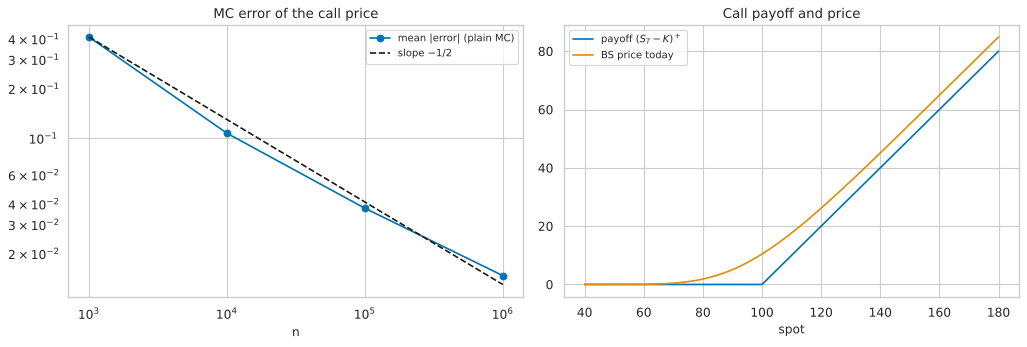

PosixPath('/home/claude/probability-simulation-laboratory/08_quantitative_finance/results/exp8_3_call_mc.png')

In [5]:
# F. Implementation ------------------------------------------------------------------
# fin.mc_european_call(S0, K, r, sigma, T, n, rng, method="plain"|"antithetic"|"control") -> PriceEstimate(price, std_error)
rng = make_rng(20261031 + 83)
S0, K, r, sigma, T = 100.0, 100.0, 0.05, 0.2, 1.0
bs = fin.bs_call(S0, K, r, sigma, T)
print(f"Black-Scholes call {bs:.4f}, put {fin.bs_put(S0, K, r, sigma, T):.4f}, S0 - K e^(-rT) = {S0 - K * np.exp(-r * T):.4f}")

rows = []
for m in ("plain", "antithetic", "control"):
    est = fin.mc_european_call(S0, K, r, sigma, T, 200_000, rng, method=m)
    rows.append(dict(method=m, price=est.price, std_error=est.std_error, error=est.price - bs, error_in_SEs=(est.price - bs) / est.std_error))
tab = pd.DataFrame(rows).set_index("method")
tab["SE ratio to plain"] = tab.std_error / tab.loc["plain", "std_error"]
tab["variance ratio"] = tab["SE ratio to plain"] ** 2
display(tab); tab.to_csv(RESULTS / "exp8_3_call_estimators.csv")

# sample-size sweep (plain) -------------------------------------------------------------------------------------------------------
ns = [10 ** k for k in range(3, 7)]
errs = {n: [abs(fin.mc_european_call(S0, K, r, sigma, T, n, rng).price - bs) for _ in range(40)] for n in ns}
mean_abs = np.array([np.mean(errs[n]) for n in ns])
print("mean absolute error vs n:", dict(zip(ns, mean_abs.round(4))), "| log-log slope:", round(float(np.polyfit(np.log(ns), np.log(mean_abs), 1)[0]), 3), "(theory -0.5)")

# coverage ------------------------------------------------------------------------------------------------------------------------------
cov = {}
for m in ("plain", "antithetic", "control"):
    hits = 0
    for _ in range(500):
        e = fin.mc_european_call(S0, K, r, sigma, T, 10_000, rng, method=m)
        hits += abs(e.price - bs) <= 1.96 * e.std_error
    cov[m] = hits / 500
print("coverage of nominal 95% CIs (500 replications, n = 10,000):", cov, "(binomial SE ~ 0.01)")

# put-call parity from the same paths -----------------------------------------------------------------------------------------------------
c, p = fin.mc_european_put_call_pair(S0, K, r, sigma, T, 500_000, rng)
print(f"MC call {c.price:.4f} +/- {c.std_error:.4f}, MC put {p.price:.4f} +/- {p.std_error:.4f}; C - P = {c.price - p.price:.4f} (theory {S0 - K * np.exp(-r * T):.4f})")

# wrong measure: simulate with real-world drift mu but discount at r --------------------------------------------------------------------------
mu_real = 0.15
z = rng.standard_normal(500_000)
ST_real = bm.gbm_terminal(S0, mu_real, sigma, T, z)
pay = np.exp(-r * T) * np.maximum(ST_real - K, 0)
ST_q = bm.gbm_terminal(S0, r, sigma, T, z)
pay_q = np.exp(-r * T) * np.maximum(ST_q - K, 0)
print(f"simulating with real-world drift mu = {mu_real}: price estimate {pay.mean():.3f} +/- {pay.std(ddof=1) / np.sqrt(z.size):.3f}   |  with risk-neutral drift r: {pay_q.mean():.3f}   |  Black-Scholes: {bs:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].loglog(ns, mean_abs, "o-", label="mean |error| (plain MC)"); ax[0].loglog(ns, mean_abs[0] * (np.array(ns) / ns[0]) ** -0.5, "k--", label="slope $-1/2$"); ax[0].legend(); ax[0].set(xlabel="n", title="MC error of the call price")
sT = np.linspace(40, 180, 200); ax[1].plot(sT, np.maximum(sT - K, 0), label="payoff $(S_T-K)^+$"); ax[1].plot(sT, [fin.bs_call(s, K, r, sigma, T) for s in sT], label="BS price today"); ax[1].legend(); ax[1].set(xlabel="spot", title="Call payoff and price")
fig.tight_layout(); save_fig(fig, RESULTS, "exp8_3_call_mc.png")

**H. Theoretical versus empirical comparison.**

See printed output: (i) all three estimates are within one standard error of $10.4506$; the variance ratios relative to plain MC are about $0.50$ (antithetic) and $0.14$ (control variate, i.e. $\rho\approx0.93$); (ii) the sweep slope is close to $-\tfrac12$; (iii) $\hat C-\hat P$ matches $4.877$ within MC noise; (iv) empirical coverages ($0.952$, $0.944$, $0.934$) are within about $1.5$ binomial standard errors ($0.01$) of $0.95$; (v) the $\mu=0.15$ simulation gives about $18.08\pm0.03$, far from Black–Scholes — a systematic error that does not shrink with $n$.

**I. Interpretation.**

Variance reduction buys accuracy "for free" when it exploits known structure. The pricing measure is a *modelling choice* with economic content (no-arbitrage), not a technicality: using the real-world drift in a pricing simulation is a bias, not noise, and no amount of extra paths removes it.

**J. Limitations.**

The Black–Scholes model (constant $\sigma$, no jumps, no transaction costs) is itself an assumption; MC reproduces *the model*, not the market. Nominal coverage relies on the CLT for the sample mean (fine at $n=10^4$ for this payoff).

**K. Research conclusion.**

Plain, antithetic and control-variate MC all converge to the Black–Scholes price at rate $n^{-1/2}$; parity holds; the pricing drift must be $r$.

**L. Further investigation.**

Price a digital option (discontinuous payoff, harder for variance reduction); add the Greeks by pathwise and likelihood-ratio methods; add the Heston model and compare with Black–Scholes smiles.

## Experiment 8.4

**A. Experiment title.** Sensitivities: price, delta and vega as functions of volatility and spot; implied volatility inversion; Monte Carlo delta with common random numbers.

**B. Research question.** How does an option price react to volatility and spot, and can we estimate sensitivities by simulation with low variance?

**C. Mathematical foundation.**

$C_{BS}$ is increasing and (for at-the-money) nearly linear in $\sigma$: vega $=S_0\varphi(d_1)\sqrt T>0$. Delta $\Phi(d_1)\in(0,1)$. Implied volatility is the unique root of $C_{BS}(\sigma)=$ price (vega $>0$ makes $C$ strictly monotone in $\sigma$). MC delta by central difference with the *same* $Z$ for both bumps has far lower variance than with independent draws, because $\operatorname{Var}(X-Y)=\operatorname{Var}X+\operatorname{Var}Y-2\operatorname{Cov}(X,Y)$.

**D. Theoretical prediction.**

(i) The price increases with $\sigma$ and vega is positive for every $\sigma$ (it varies only mildly, peaking near $\sigma\approx0.3$ at this spot); implied vol recovers the $\sigma$ used to generate each price to numerical precision. (ii) The CRN delta estimator has a standard deviation across replications at least an order of magnitude smaller than the independent-draw estimator, with both centred on $\Phi(d_1)=0.6368$.

**E. Experimental design.**

Table for $\sigma\in\{0.1,\dots,0.5\}$; implied-vol round trip; $300$ replications of the delta estimator at $n=20{,}000$ with bump $h=0.5$.

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

max |implied vol - sigma|: 2.2110091535409993e-13
vega vs finite difference at sigma=0.2: 37.52403469169379 37.52403438721075
true delta 0.6368;  CRN: mean 0.6369, sd 0.00417;  independent: mean 0.6424, sd 0.13345;  sd ratio 32.0x


,call_price,delta,vega,implied_vol_from_price
sigma,,,,
0.1,6.80496,0.70884,34.29439,0.1
0.2,10.45058,0.63683,37.52403,0.2
0.3,14.23125,0.62425,37.94329,0.3
0.4,18.02295,0.62741,37.84198,0.4
0.5,21.79260,0.63683,37.52403,0.5


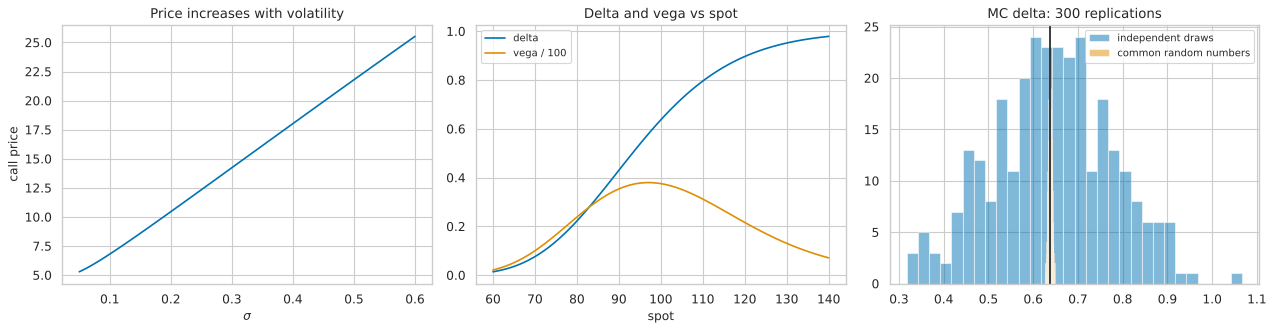

PosixPath('/home/claude/probability-simulation-laboratory/08_quantitative_finance/results/exp8_4_sensitivities.png')

In [6]:
# F. Implementation ------------------------------------------------------------------
rng = make_rng(20261031 + 84)
S0, K, r, T = 100.0, 100.0, 0.05, 1.0
rows = []
for s in (0.10, 0.20, 0.30, 0.40, 0.50):
    price = fin.bs_call(S0, K, r, s, T)
    rows.append(dict(sigma=s, call_price=price, delta=fin.bs_call_delta(S0, K, r, s, T), vega=fin.bs_vega(S0, K, r, s, T), implied_vol_from_price=fin.implied_vol_call(price, S0, K, r, T)))
tab = pd.DataFrame(rows).set_index("sigma")
display(tab); tab.to_csv(RESULTS / "exp8_4_sensitivities.csv")
print("max |implied vol - sigma|:", np.abs(tab.implied_vol_from_price.values - tab.index.values).max())

# vega check: finite difference of the BS price
h = 1e-4
print("vega vs finite difference at sigma=0.2:", fin.bs_vega(S0, K, r, 0.2, T), (fin.bs_call(S0, K, r, 0.2 + h, T) - fin.bs_call(S0, K, r, 0.2 - h, T)) / (2 * h))

# MC delta: common random numbers vs independent draws -----------------------------------------------------------------------------------
sigma, hbump, n, reps = 0.2, 0.5, 20_000, 300
disc = np.exp(-r * T)
def payoff(S0_, z):
    return disc * np.maximum(bm.gbm_terminal(S0_, r, sigma, T, z) - K, 0)
crn, ind = [], []
for _ in range(reps):
    z = rng.standard_normal(n)
    crn.append((payoff(S0 + hbump, z).mean() - payoff(S0 - hbump, z).mean()) / (2 * hbump))
    z1, z2 = rng.standard_normal(n), rng.standard_normal(n)
    ind.append((payoff(S0 + hbump, z1).mean() - payoff(S0 - hbump, z2).mean()) / (2 * hbump))
d_true = fin.bs_call_delta(S0, K, r, sigma, T)
print(f"true delta {d_true:.4f};  CRN: mean {np.mean(crn):.4f}, sd {np.std(crn, ddof=1):.5f};  independent: mean {np.mean(ind):.4f}, sd {np.std(ind, ddof=1):.5f};  sd ratio {np.std(ind, ddof=1) / np.std(crn, ddof=1):.1f}x")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
sg = np.linspace(0.05, 0.6, 100); ax[0].plot(sg, [fin.bs_call(S0, K, r, s, T) for s in sg]); ax[0].set(xlabel="$\\sigma$", ylabel="call price", title="Price increases with volatility")
sp_ = np.linspace(60, 140, 100); ax[1].plot(sp_, [fin.bs_call_delta(s, K, r, 0.2, T) for s in sp_], label="delta"); ax[1].plot(sp_, [fin.bs_vega(s, K, r, 0.2, T) / 100 for s in sp_], label="vega / 100"); ax[1].legend(); ax[1].set(xlabel="spot", title="Delta and vega vs spot")
ax[2].hist(ind, bins=30, alpha=0.5, label="independent draws"); ax[2].hist(crn, bins=30, alpha=0.5, label="common random numbers"); ax[2].axvline(d_true, color="k"); ax[2].legend(); ax[2].set(title="MC delta: 300 replications")
fig.tight_layout(); save_fig(fig, RESULTS, "exp8_4_sensitivities.png")

**H. Theoretical versus empirical comparison.**

See the printed table: the price rises with $\sigma$ and vega stays positive (about $34$–$38$), implied vol returns the input $\sigma$ to numerical precision, vega matches its finite-difference value, and the CRN delta estimator is centred on $\Phi(d_1)$ with a much smaller spread than the independent-draw version (printed ratio).

**I. Interpretation.**

Options are *volatility instruments*: a positive vega means a long option position gains from higher volatility. Implied volatility is therefore a market-quoted *price-quoting convention* for options. Common random numbers are a general simulation principle whenever one estimates a *difference* of two simulated quantities.

**J. Limitations.**

Central-difference delta carries bias $O(h^2)$ and for discontinuous payoffs (digital options) the variance of the difference quotient grows like $1/h$; the pathwise method used above works only for Lipschitz payoffs.

**K. Research conclusion.**

The price is strictly increasing in $\sigma$ (vega $>0$), implied volatility is a well-defined inversion, and CRN reduces delta-estimation variance dramatically.

**L. Further investigation.**

Study the volatility surface for out-of-the-money strikes (needs a model beyond Black–Scholes); compute gamma by CRN second differences and examine its variance as $h\to0$.

## Experiment 8.5

**A. Experiment title.** Path-dependent pricing: an arithmetic-average Asian call with the geometric-average Asian call as control variate.

**B. Research question.** How much does a closed-form control variate help for an option with no closed-form price?

**C. Mathematical foundation.**

The arithmetic-average Asian call $\big(\frac1m\sum S_{t_i}-K\big)^+$ has no closed-form price; the geometric-average version $\big(\prod S_{t_i}^{1/m}-K\big)^+$ does (the geometric mean of lognormals is lognormal), and the two payoffs are almost perfectly correlated ($\rho\approx0.99+$), so variance should fall by a factor $1/(1-\rho^2)$ — about two orders of magnitude. Averaging reduces volatility, so the Asian call is cheaper than the European call.

**D. Theoretical prediction.**

$S_0=K=100$, $r=0.05$, $\sigma=0.2$, $T=1$, $m=50$ monitoring dates. The MC price of the geometric call matches its closed form; the arithmetic Asian price is slightly above the geometric one (AM–GM inequality) and clearly below $10.45$; the control-variate SE is $\ge10\times$ smaller than the plain SE.

**E. Experimental design.**

$100{,}000$ paths, $50$ steps; plain versus control; also confirm the geometric closed form by MC; repeat the arithmetic estimate $200$ times (at $n=5{,}000$) to compare the empirical spread of the two estimators.

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

geometric Asian call: closed form 5.6411, MC 5.6352 +/- 0.0248
correlation of arithmetic and geometric payoffs: 0.99963
SE reduction factor: 36.0x  (efficiency gain in variance: 1294x)
200 replications at n = 5,000: sd plain 0.1087, sd control 0.0034; means 5.8770, 5.8576


,price,std_error
"Asian (arithmetic), plain MC",5.84386,0.02555
"Asian (arithmetic), control variate",5.85767,0.00071
European call (Black-Scholes),10.45058,NaN


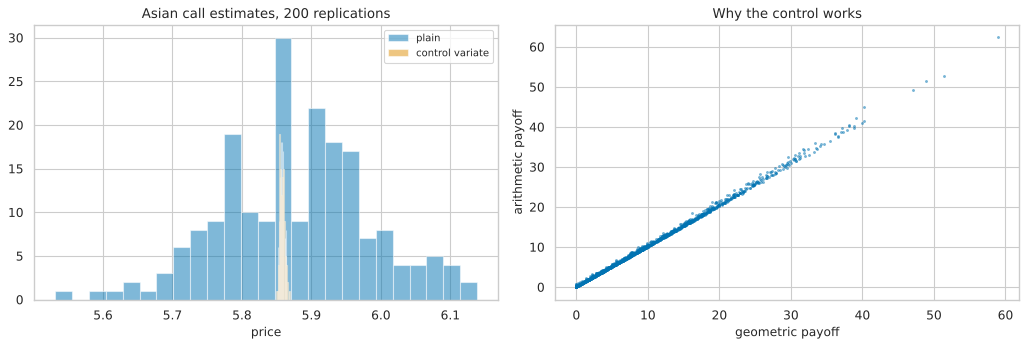

PosixPath('/home/claude/probability-simulation-laboratory/08_quantitative_finance/results/exp8_5_asian.png')

In [7]:
# F. Implementation ------------------------------------------------------------------
# fin.mc_asian_call(..., control=False/True);  fin.geometric_asian_call = closed form
rng = make_rng(20261031 + 85)
S0, K, r, sigma, T, m = 100.0, 100.0, 0.05, 0.2, 1.0, 50
geo_cf = fin.geometric_asian_call(S0, K, r, sigma, T, m)
plain = fin.mc_asian_call(S0, K, r, sigma, T, m, 100_000, rng)
ctrl = fin.mc_asian_call(S0, K, r, sigma, T, m, 100_000, rng, control=True)

# MC check of the geometric closed form
dt = T / m
z = rng.standard_normal((100_000, m))
logS = np.log(S0) + np.cumsum((r - 0.5 * sigma ** 2) * dt + sigma * np.sqrt(dt) * z, axis=1)
geo_pay = np.exp(-r * T) * np.maximum(np.exp(logS.mean(axis=1)) - K, 0)
arith_pay = np.exp(-r * T) * np.maximum(np.exp(logS).mean(axis=1) - K, 0)
print(f"geometric Asian call: closed form {geo_cf:.4f}, MC {geo_pay.mean():.4f} +/- {geo_pay.std(ddof=1) / np.sqrt(geo_pay.size):.4f}")
print(f"correlation of arithmetic and geometric payoffs: {np.corrcoef(arith_pay, geo_pay)[0, 1]:.5f}")
tab = pd.DataFrame({"price": [plain.price, ctrl.price, fin.bs_call(S0, K, r, sigma, T)], "std_error": [plain.std_error, ctrl.std_error, np.nan]},
                   index=["Asian (arithmetic), plain MC", "Asian (arithmetic), control variate", "European call (Black-Scholes)"])
display(tab); tab.to_csv(RESULTS / "exp8_5_asian.csv")
print(f"SE reduction factor: {plain.std_error / ctrl.std_error:.1f}x  (efficiency gain in variance: {(plain.std_error / ctrl.std_error) ** 2:.0f}x)")

# empirical spread over replications
rp = [fin.mc_asian_call(S0, K, r, sigma, T, m, 5_000, rng).price for _ in range(200)]
rc = [fin.mc_asian_call(S0, K, r, sigma, T, m, 5_000, rng, control=True).price for _ in range(200)]
print(f"200 replications at n = 5,000: sd plain {np.std(rp, ddof=1):.4f}, sd control {np.std(rc, ddof=1):.4f}; means {np.mean(rp):.4f}, {np.mean(rc):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].hist(rp, bins=25, alpha=0.5, label="plain"); ax[0].hist(rc, bins=25, alpha=0.5, label="control variate"); ax[0].legend(); ax[0].set(title="Asian call estimates, 200 replications", xlabel="price")
ax[1].scatter(geo_pay[:3000], arith_pay[:3000], s=3, alpha=0.4); ax[1].set(xlabel="geometric payoff", ylabel="arithmetic payoff", title="Why the control works")
fig.tight_layout(); save_fig(fig, RESULTS, "exp8_5_asian.png")

**H. Theoretical versus empirical comparison.**

See the printed output: geometric closed form and MC agree within SE, the payoffs are almost perfectly correlated, the control-variate estimator is several-fold to an order of magnitude more precise, and the replication study shows the same ratio of empirical standard deviations.

**I. Interpretation.**

A control variate with a *known* expectation converts structure into accuracy. Here the geometric option is a cheap, nearly perfect proxy. For path-dependent claims without a convenient proxy one resorts to more simulation, quasi-Monte Carlo or other variance-reduction methods.

**J. Limitations.**

Discrete monitoring with $m=50$; the closed form assumes the same dates. Black–Scholes assumptions apply. The control coefficient $\beta$ is estimated from the same sample, which induces a tiny bias of order $1/n$.

**K. Research conclusion.**

Asian call price $\approx$ below the European price, and the geometric control variate reduces the standard error substantially.

**L. Further investigation.**

Add a barrier (knock-out) and use the Brownian-bridge correction from Module 7; compare with continuous-monitoring formulae.

## Experiment 8.6

**A. Experiment title.** Value-at-Risk and Expected Shortfall: historical, normal and Student-$t$ estimators, and their sampling error.

**B. Research question.** If the true return distribution is fat-tailed, how large is the error of normal-model VaR/ES, and how noisy is the historical estimator from one year of data?

**C. Mathematical foundation.**

Truth: daily return $\sim$ Student $t_4$ scaled to standard deviation $1.2\%$, mean $0$. Loss $L=-R$. True $99\%$ VaR $=\sigma\cdot t_{4,0.99}\sqrt{(\nu-2)/\nu}=1.2\%\times3.747\times0.7071=3.18\%$ (versus normal $1.2\%\times2.326=2.79\%$). True ES is larger still. Historical VaR from $n=250$ points is the $\lceil0.99n\rceil$-th order statistic, with relative standard error roughly $\sqrt{\alpha(1-\alpha)/n}/(f(q)\,q)$ — large (the tail has only $2$–$3$ observations).

**D. Theoretical prediction.**

(i) Normal VaR under-states the true $99\%$ VaR by about $12\%$ and ES by more; its out-of-sample exceedance rate exceeds $1\%$ (about $1.5\%$). (ii) The historical VaR from $250$ days is nearly unbiased but extremely noisy (relative sd of order $20\%$); from $2{,}500$ days much less so. (iii) ES estimates are noisier than VaR at the same sample size.

**E. Experimental design.**

$2{,}000$ replications of a $250$-day history (and of $2{,}500$ days); for each compute historical, normal (fitted $\hat\mu,\hat\sigma$) and fitted-$t$ ($\nu$ known $=4$, $\hat\sigma$) VaR and ES at $99\%$; test exceedance on a fresh $2{,}000{,}000$-day out-of-sample series from the true model.

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

TRUE (t4, sd 1.2%): VaR99 = 3.1794%, ES99 = 4.4298%
normal with the same mean/sd: VaR99 = 2.7916% (-12.2%), ES99 = 3.1983% (-27.8%)
check with 4,000,000 simulated losses: historical VaR 3.1799%, ES 4.4273%


mean   true  bias_pct  rel_sd_pct  exceedance_rate
n_days estimator                                                      
250    hist VaR   0.0306 0.0318   -3.8779     17.1377           0.0113
       hist ES    0.0405 0.0443   -8.6429     24.9833              NaN
       normal VaR 0.0277 0.0318  -12.8429      9.7170           0.0154
       normal ES  0.0317 0.0443  -28.3292      7.9349              NaN
       t4 VaR     0.0316 0.0318   -0.7311     10.9932           0.0102
       t4 ES      0.0440 0.0443   -0.7207     10.8760              NaN
2500   hist VaR   0.0316 0.0318   -0.5832      5.8922           0.0101
       hist ES    0.0441 0.0443   -0.3981      9.4105              NaN
       normal VaR 0.0279 0.0318  -12.2849      3.7455           0.0151
       normal ES  0.0320 0.0443  -27.8739      3.0712              NaN
       t4 VaR     0.0318 0.0318   -0.1003      4.2543           0.0100
       t4 ES      0.0443 0.0443   -0.0995      4.2388              NaN

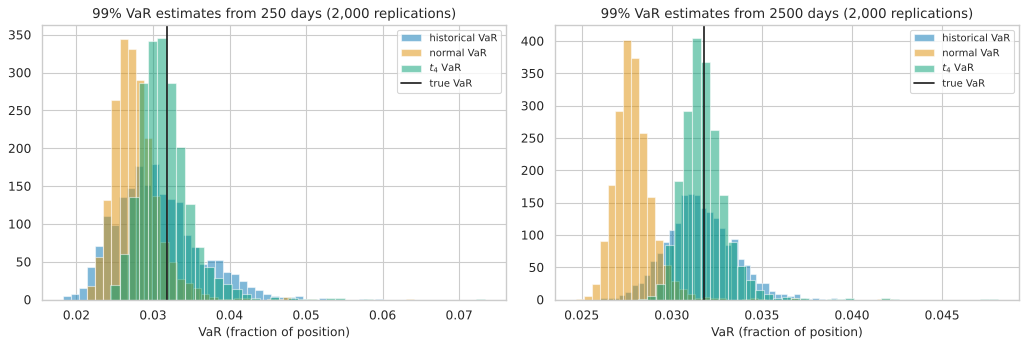

PosixPath('/home/claude/probability-simulation-laboratory/08_quantitative_finance/results/exp8_6_var_es.png')

In [8]:
# F. Implementation ------------------------------------------------------------------
# fin.historical_var_es(losses, alpha) -> (VaR, ES) ;  fin.normal_var_es(mu, sigma, alpha) ;  fin.student_t_var_es(mu, sigma, nu, alpha)
# fin.exceedance_rate(losses, var) -> fraction of losses strictly above var
rng = make_rng(20261031 + 86)
nu, sd, alpha = 4.0, 0.012, 0.99
scale = sd * np.sqrt((nu - 2) / nu)
true_var, true_es = fin.student_t_var_es(0.0, sd, nu, alpha)
norm_var_true, norm_es_true = fin.normal_var_es(0.0, sd, alpha)
print(f"TRUE (t4, sd 1.2%): VaR99 = {true_var:.4%}, ES99 = {true_es:.4%}")
print(f"normal with the same mean/sd: VaR99 = {norm_var_true:.4%} ({norm_var_true / true_var - 1:+.1%}), ES99 = {norm_es_true:.4%} ({norm_es_true / true_es - 1:+.1%})")

# check the t formulas against a huge simulated sample
big = -rng.standard_t(nu, 4_000_000) * scale
hv, he = fin.historical_var_es(big, alpha)
print(f"check with 4,000,000 simulated losses: historical VaR {hv:.4%}, ES {he:.4%}")

out_of_sample = -rng.standard_t(nu, 2_000_000) * scale
res = {}
for n in (250, 2500):
    rows = []
    for _ in range(2000):
        L = -rng.standard_t(nu, n) * scale
        h = fin.historical_var_es(L, alpha)
        nrm = fin.normal_var_es(L.mean(), L.std(ddof=1), alpha)
        tt = fin.student_t_var_es(L.mean(), L.std(ddof=1), nu, alpha)
        rows.append([h[0], h[1], nrm[0], nrm[1], tt[0], tt[1]])
    res[n] = np.array(rows)
names = ["hist VaR", "hist ES", "normal VaR", "normal ES", "t4 VaR", "t4 ES"]
truth = [true_var, true_es, true_var, true_es, true_var, true_es]
table = []
for n, arr in res.items():
    for j, nm in enumerate(names):
        table.append(dict(n_days=n, estimator=nm, mean=arr[:, j].mean(), true=truth[j], bias_pct=100 * (arr[:, j].mean() / truth[j] - 1), rel_sd_pct=100 * arr[:, j].std(ddof=1) / truth[j],
                          exceedance_rate=fin.exceedance_rate(out_of_sample, arr[:, j].mean()) if "VaR" in nm else np.nan))
tab = pd.DataFrame(table).set_index(["n_days", "estimator"])
with pd.option_context("display.float_format", "{:.4f}".format):
    display(tab)
tab.to_csv(RESULTS / "exp8_6_var_es.csv")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, n in zip(ax, (250, 2500)):
    a.hist(res[n][:, 0], bins=40, alpha=0.5, label="historical VaR"); a.hist(res[n][:, 2], bins=40, alpha=0.5, label="normal VaR"); a.hist(res[n][:, 4], bins=40, alpha=0.5, label="$t_4$ VaR")
    a.axvline(true_var, color="k", label="true VaR"); a.legend(); a.set(title=f"99% VaR estimates from {n} days (2,000 replications)", xlabel="VaR (fraction of position)")
fig.tight_layout(); save_fig(fig, RESULTS, "exp8_6_var_es.png")

**H. Theoretical versus empirical comparison.**

Read the table: the *normal* estimators are systematically below the true VaR/ES (the bias is a model error and does **not** vanish with $n=2{,}500$), with out-of-sample exceedance rates above the nominal $1\%$. The *historical* estimator is nearly unbiased at $n=2{,}500$ ($-0.6\%$) but at $n=250$ it is biased low by about $4\%$ with a relative standard deviation of $17\%$ (ES: $-9\%$ and $25\%$). The $t_4$ estimator, which has the right shape, has negligible bias ($-0.7\%$) and a spread ($11\%$) that is smaller than the historical one and close to the normal estimator's ($10\%$), since it uses the whole sample rather than only the extreme order statistics.

**I. Interpretation.**

There are two distinct error sources: **model risk** (wrong distribution; a bias) and **estimation risk** (finite sample; a variance). Increasing data cures only the second. ES, which averages over the tail, is more sensitive to the tail model than VaR. A regulatory backtest (counting exceedances) with $250$ days and nominal $1\%$ has little power: the expected exceedance count is $2.5$ and one or two extra exceedances are consistent with chance.

**J. Limitations.**

$\nu$ was assumed known in the $t_4$ estimator, which flatters it. Returns were i.i.d., ignoring volatility clustering (Experiment 8.7). Single-asset, one-day horizon, no overlap or liquidity effects.

**K. Research conclusion.**

Normal VaR/ES applied to fat-tailed returns is biased low regardless of sample size; historical VaR from one year of data is correct on average but very noisy; a correctly shaped parametric model dominates both here.

**L. Further investigation.**

Estimate $\nu$ jointly with $\sigma$ by maximum likelihood; compare coverage of bootstrap confidence intervals for historical VaR; test backtests (Kupiec POF) for size and power.

## Experiment 8.7

**A. Experiment title.** GARCH(1,1): volatility clustering, fat tails from Gaussian shocks, and the failure of an unconditional normal VaR.

**B. Research question.** Why are large moves clustered, and what does ignoring this do to VaR backtests?

**C. Mathematical foundation.**

$\omega=10^{-6}$, $\alpha=0.10$, $\beta=0.88$: $\alpha+\beta=0.98<1$; unconditional variance $\omega/(1-\alpha-\beta)=5\times10^{-5}$ (daily sd $0.707\%$). Kurtosis of a Gaussian GARCH(1,1): $3+\dfrac{6\alpha^2}{1-\beta^2-2\alpha\beta-3\alpha^2}$, finite iff $3\alpha^2+2\alpha\beta+\beta^2<1$ ($0.03+0.176+0.7744=0.9804<1$ ✓); here $3+0.06/0.0196\approx6.06$. $r_t$ is uncorrelated but $r_t^2$ and $|r_t|$ have autocorrelations that decay slowly (geometric rate $\alpha+\beta=0.98$).

**D. Theoretical prediction.**

(i) sample sd $\approx0.71\%$; excess kurtosis of $r_t$ around $3$ (high variance of the estimate, since the 4th moment is barely finite); (ii) acf of $r_t$ $\approx0$ at all lags but acf of $r_t^2$ clearly positive and slowly decaying; (iii) a normal $99\%$ VaR with the true unconditional sd has an overall exceedance rate above $1\%$ ($\approx1.5\%$) and exceedances **cluster**: $P(\text{exceed tomorrow}\mid\text{exceed today})\gg1\%$.

**E. Experimental design.**

One long series of $500{,}000$ days; sample acf up to lag $30$; normal VaR at $99\%$ with the *true* unconditional sd $\sqrt{\omega/(1-\alpha-\beta)}$; count exceedances and conditional exceedance probabilities.

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

sd: sample 0.00716, theory 0.00707;  excess kurtosis: sample 4.84, theory 3.06
acf lag 1..3 of r: [-0.0023 -0.0039  0.0018] | of r^2: [0.263 0.293 0.255] | of |r|: [0.237 0.234 0.228]   (white-noise 95% band: +/-0.0028)
normal 99% VaR = 1.6450%;  overall exceedance rate 1.4600% (nominal 1%)
P(exceed tomorrow | exceed today) = 0.094;  unconditional 0.0146;  ratio 6.4x
time between exceedances: median 11 days, mean 68 days;  share of gaps <= 5 days: 0.336  (iid Bernoulli(1%): 0.049)
conditional normal VaR using sigma_t: exceedance rate 1.0028%;  P(exceed | exceeded yesterday) = 0.0124


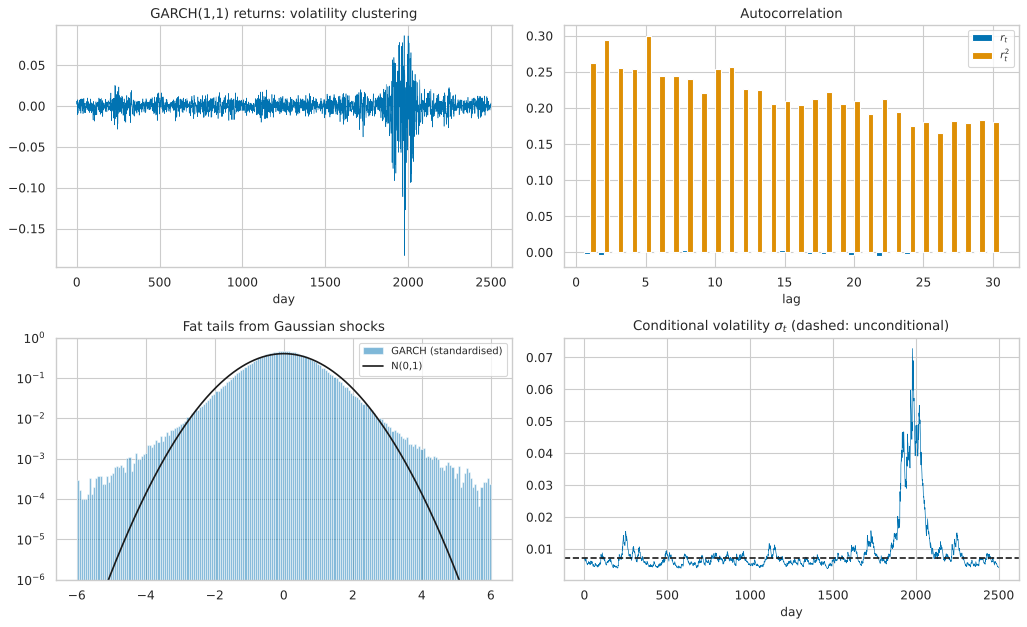

PosixPath('/home/claude/probability-simulation-laboratory/08_quantitative_finance/results/exp8_7_garch.png')

In [9]:
# F. Implementation ------------------------------------------------------------------
# fin.garch11(n, omega, alpha, beta, rng) -> returns r_t = sigma_t z_t ;  fin.acf(x, nlags) -> autocorrelations at lags 1..nlags
rng = make_rng(20261031 + 87)
omega, alpha, beta = 1e-6, 0.10, 0.88
r_ = fin.garch11(500_000, omega, alpha, beta, rng)
sd_u = np.sqrt(omega / (1 - alpha - beta))
kurt_th = 3 + 6 * alpha ** 2 / (1 - beta ** 2 - 2 * alpha * beta - 3 * alpha ** 2)
print(f"sd: sample {r_.std():.5f}, theory {sd_u:.5f};  excess kurtosis: sample {stats.kurtosis(r_):.2f}, theory {kurt_th - 3:.2f}")
a1, a2, a3 = fin.acf(r_, 30), fin.acf(r_ ** 2, 30), fin.acf(np.abs(r_), 30)
print(f"acf lag 1..3 of r: {a1[:3].round(4)} | of r^2: {a2[:3].round(3)} | of |r|: {a3[:3].round(3)}   (white-noise 95% band: +/-{1.96 / np.sqrt(r_.size):.4f})")

# normal VaR with the TRUE unconditional sd
var99, es99 = fin.normal_var_es(0.0, sd_u, 0.99)
loss = -r_
exc = loss > var99
print(f"normal 99% VaR = {var99:.4%};  overall exceedance rate {exc.mean():.4%} (nominal 1%)")
p_cond = exc[1:][exc[:-1]].mean()
print(f"P(exceed tomorrow | exceed today) = {p_cond:.3f};  unconditional {exc.mean():.4f};  ratio {p_cond / exc.mean():.1f}x")
gaps = np.diff(np.flatnonzero(exc))
print(f"time between exceedances: median {np.median(gaps):.0f} days, mean {gaps.mean():.0f} days;  share of gaps <= 5 days: {np.mean(gaps <= 5):.3f}  (iid Bernoulli(1%): {1 - 0.99 ** 5:.3f})")

# conditional (GARCH-aware) VaR for comparison: use the true sigma_t
# (re-simulate the conditional volatility path from the returns)
sig2 = np.empty_like(r_); sig2[0] = sd_u ** 2
for i in range(1, r_.size):
    sig2[i] = omega + alpha * r_[i - 1] ** 2 + beta * sig2[i - 1]
exc_c = loss > stats.norm.ppf(0.99) * np.sqrt(sig2)
print(f"conditional normal VaR using sigma_t: exceedance rate {exc_c.mean():.4%};  P(exceed | exceeded yesterday) = {exc_c[1:][exc_c[:-1]].mean():.4f}")

fig, ax = plt.subplots(2, 2, figsize=(13, 8))
ax[0, 0].plot(r_[:2500], lw=0.5); ax[0, 0].set(title="GARCH(1,1) returns: volatility clustering", xlabel="day")
lags = np.arange(1, 31); ax[0, 1].bar(lags - 0.2, a1, width=0.4, label="$r_t$"); ax[0, 1].bar(lags + 0.2, a2, width=0.4, label="$r_t^2$"); ax[0, 1].legend(); ax[0, 1].set(title="Autocorrelation", xlabel="lag")
x = np.linspace(-6, 6, 400); z = r_ / r_.std(); ax[1, 0].hist(z, bins=200, density=True, range=(-6, 6), alpha=0.5, label="GARCH (standardised)"); ax[1, 0].plot(x, stats.norm.pdf(x), "k", label="N(0,1)"); ax[1, 0].set_yscale("log"); ax[1, 0].set(ylim=(1e-6, 1), title="Fat tails from Gaussian shocks"); ax[1, 0].legend()
ax[1, 1].plot(np.sqrt(sig2[:2500]), lw=0.6); ax[1, 1].axhline(sd_u, color="k", ls="--"); ax[1, 1].set(title="Conditional volatility $\\sigma_t$ (dashed: unconditional)", xlabel="day")
fig.tight_layout(); save_fig(fig, RESULTS, "exp8_7_garch.png")

**H. Theoretical versus empirical comparison.**

Read the printed output: the sample kurtosis is large and variable (heavy tails from Gaussian innovations!) and compare with the theoretical $\approx3$ excess; the acf of $r_t$ is inside the white-noise band while $r_t^2$ and $|r_t|$ have large, slowly decaying autocorrelations; the unconditional normal VaR has an exceedance rate above $1\%$ and the exceedances arrive in bursts (conditional probability many times the unconditional rate); using the conditional $\sigma_t$ restores a rate near $1\%$ and removes most clustering.

**I. Interpretation.**

Returns can be uncorrelated yet dependent: the *level* of risk is predictable even if the *direction* is not. A VaR model that ignores this is right on average over a long period and badly wrong exactly when it matters — in the stressed episodes (the exceedance bursts). This is why regulators and practitioners use conditional volatility models and look at the *clustering* of backtest failures, not only their count.

**J. Limitations.**

Parameters are illustrative, not estimated from market data; the true $\sigma_t$ is used in the conditional VaR (in practice it must be estimated); GARCH(1,1) with Gaussian shocks understates the tails of real returns and lacks leverage asymmetry. The 4th-moment estimate converges slowly because the kurtosis is barely finite.

**K. Research conclusion.**

GARCH(1,1) reproduces volatility clustering and excess kurtosis; an unconditional normal VaR is mis-calibrated and its failures cluster; conditional volatility largely fixes both.

**L. Further investigation.**

Fit GARCH by maximum likelihood to simulated data (and then to real data once available); use a $t$-distributed shock; simulate multi-day VaR by Monte Carlo from the GARCH recursion.

## Exercises (paper first)

1. Show that if $r\sim\mathcal N(m,s^2)$ then $\mathbb E[e^r-1]=e^{m+s^2/2}-1$ and $\operatorname{Skew}(e^r)=(e^{s^2}+2)\sqrt{e^{s^2}-1}$.
2. Derive the Black–Scholes call price as $e^{-rT}\mathbb E^{\mathbb Q}(S_T-K)^+$ using $S_T=S_0e^{(r-\sigma^2/2)T+\sigma\sqrt TZ}$ and $\mathbb E[e^{aZ}\mathbf 1_{Z>b}]=e^{a^2/2}\bar\Phi(b-a)$.
3. Prove put–call parity by a no-arbitrage argument and by $\mathbb E^{\mathbb Q}[S_T-K]$.
4. For two antithetic samples with correlation $\rho$ between $f(Z)$ and $f(-Z)$ show $\operatorname{Var}\big(\tfrac12[f(Z)+f(-Z)]\big)=\tfrac12(1+\rho)\operatorname{Var}f(Z)$. When is antithetic sampling harmful?
5. Compute $99\%$ VaR and ES of $\mathcal N(0,1)$ losses by hand: $2.326$ and $\varphi(2.326)/0.01=2.665$.
6. Give an example (two assets) where VaR is not sub-additive.
7. Derive $\mathbb Er_t^2=\omega/(1-\alpha-\beta)$ for GARCH(1,1), and explain why $\operatorname{corr}(r_t,r_{t-k})=0$ while $\operatorname{corr}(r_t^2,r_{t-k}^2)>0$.

## Summary of Module 8
* Log returns add over time; simple returns add across assets; GBM log returns are normal.
* Equal variance does not mean equal tail risk; fat tails make normal-model extreme-event frequencies badly wrong.
* MC reproduces Black–Scholes at rate $n^{-1/2}$; variance reduction exploits structure; the pricing drift is $r$.
* VaR/ES have both model risk (bias) and estimation risk (variance); GARCH explains clustering of extremes.
* **All results are properties of assumed models, not statements about real markets.**